# EfficientNetV2 — Smaller Models and Faster Training

**Paper:** Tan, M., & Le, Q. V. (2021). EfficientNetV2: Smaller Models and Faster Training. *ICML 2021*. https://arxiv.org/abs/2104.00298

**EfficientNetV1:** Tan, M., & Le, Q. V. (2019). EfficientNet: Rethinking Model Scaling for CNNs. *ICML 2019*. https://arxiv.org/abs/1905.11946

**Implementation:** `hale_core/nn/vision/cnn/efficientnet.py`

> EfficientNetV2 replaces the initial MBConv stages with FusedMBConv blocks — fusing the expand and depthwise operations into a single 3×3 conv — achieving significantly faster training while maintaining high accuracy.

> 📄 **Paper:** Tan & Le (2021). EfficientNetV2: Smaller Models and Faster Training. ICML 2021.
> 🔗 **Link:** <https://arxiv.org/abs/2104.00298>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/efficientnet.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, H, W)"]:::io --> STEM["conv 3×3 /2 → 24"]:::stage
  STEM --> FM["early stages: Fused-MBConv<br/>(3×3 conv expand, no depthwise)"]:::stage --> MB["late stages: MBConv + SE"]:::stage
  MB --> HEAD["1×1 conv → 1280"]:::block --> GAP["avg pool"]:::block --> OUT
  subgraph FUSED["Fused-MBConv"]
    direction LR
    X["x"] --> C3["3×3 conv expand · BN · SiLU"]:::block --> P["1×1 project · BN"]:::block --> ADD(("+"))
    X --> ADD
  end
  FM -.-> FUSED
  PL["progressive learning: small images + weak regularisation → large images + strong"]:::block -.-> FM
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Overview

```
Input [B, 3, H, W]
  → Stem: 3×3 stride-2 conv + BN + SiLU         [B, 24, H/2, W/2]

EfficientNetV2-S Stage Structure:
  Stage 0: FusedMBConv, r=1, k=3, stride=1, C=24,  n=2  → [B,  24, H/2, W/2]
  Stage 1: FusedMBConv, r=4, k=3, stride=2, C=48,  n=4  → [B,  48, H/4, W/4]
  Stage 2: FusedMBConv, r=4, k=3, stride=2, C=64,  n=4  → [B,  64, H/8, W/8]
  Stage 3: MBConv,      r=4, k=3, stride=2, C=128, n=6  → [B, 128, H/16,W/16]
  Stage 4: MBConv,      r=6, k=3, stride=1, C=160, n=9  → [B, 160, H/16,W/16]
  Stage 5: MBConv,      r=6, k=3, stride=2, C=256, n=15 → [B, 256, H/32,W/32]
  Head:    1×1 conv + BN + SiLU                         → [B,1280, H/32,W/32]
  GlobalAvgPool → [B, 1280]

FusedMBConv (early stages — fused expand+depthwise):
  x → 3×3 Conv (expand) → BN → SiLU
    → [SE block if se_ratio]
    → 1×1 Conv (project) → BN
    → (+residual if same dim) via StochasticDepth

MBConv (late stages — factored expand+depthwise):
  x → 1×1 Conv (expand) → BN → SiLU
    → DW 3×3 Conv → BN → SiLU
    → SE block
    → 1×1 Conv (project) → BN
    → (+residual if same dim) via StochasticDepth

Squeeze-Excite (SE):
  x → GlobalAvgPool → fc1 (C//4) → SiLU → fc2 (C) → Sigmoid → scale x
```

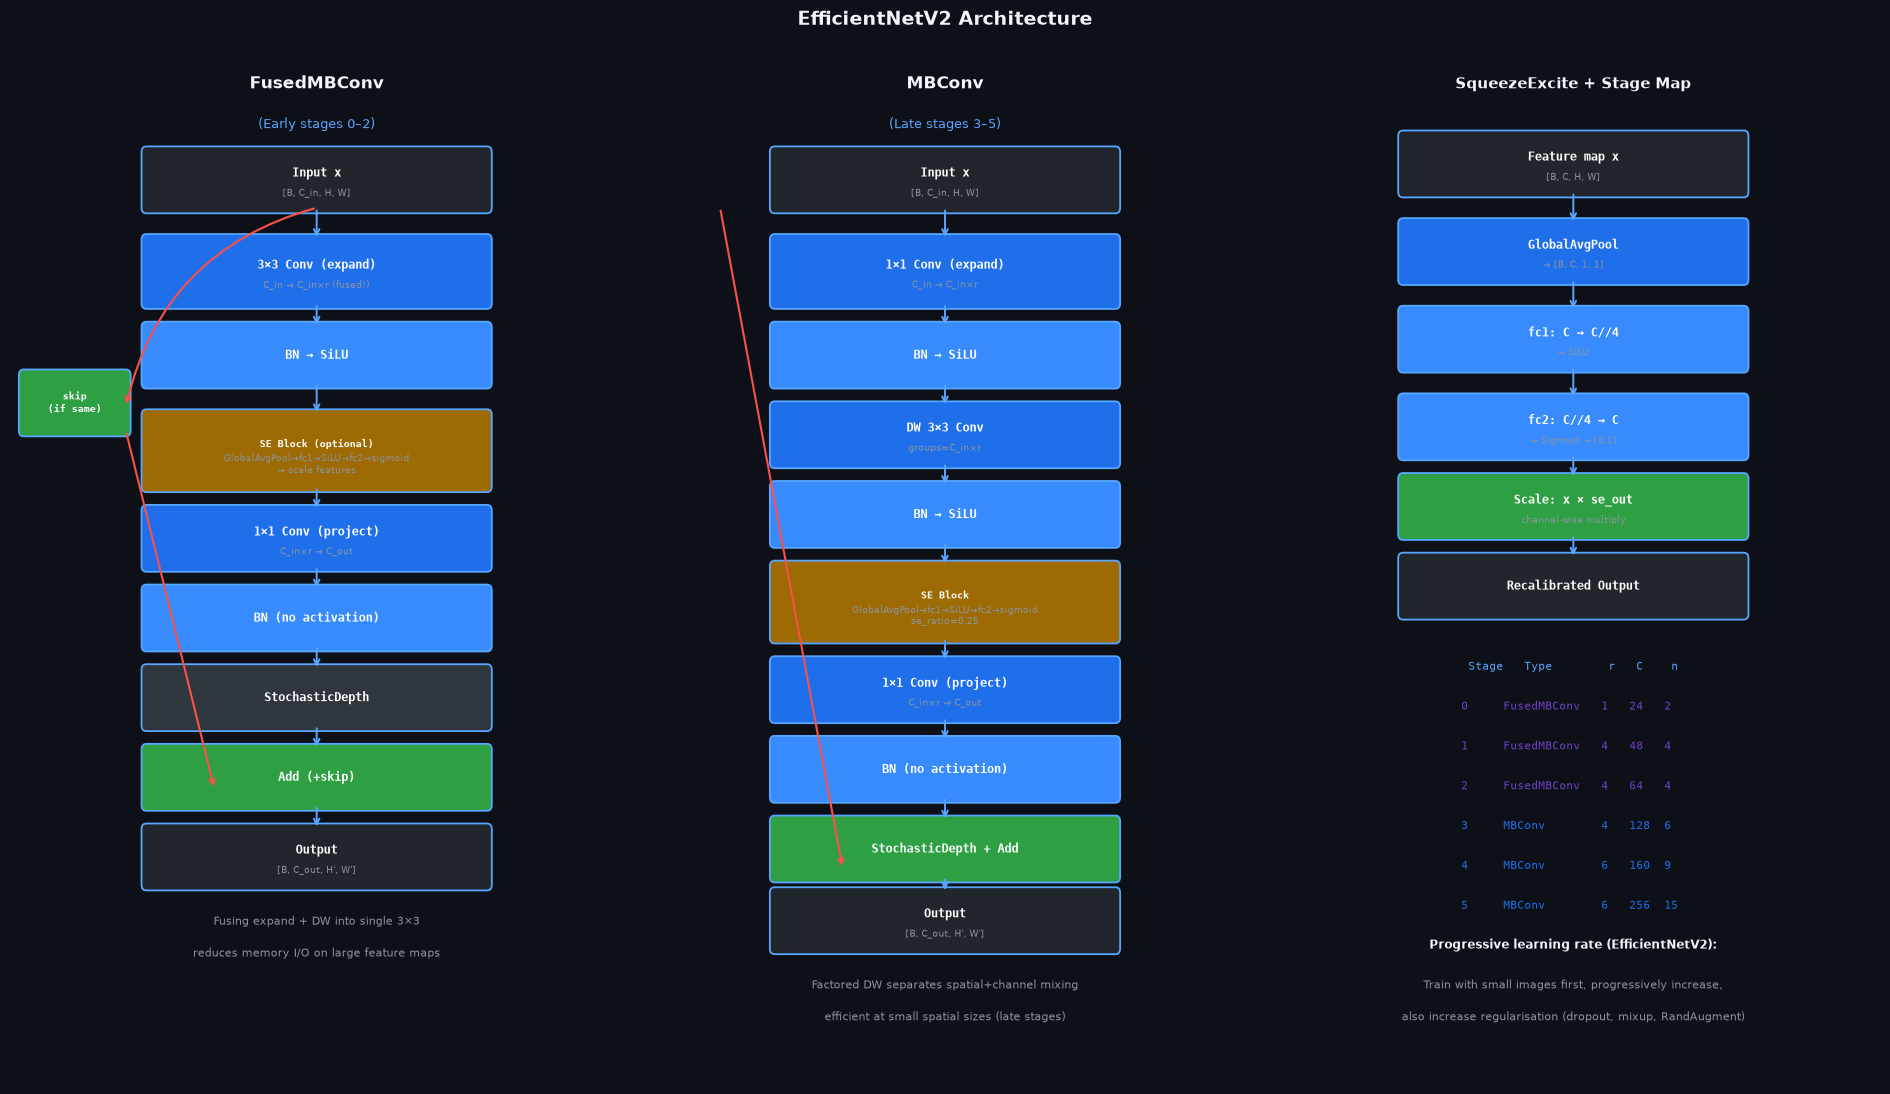

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(19, 11))
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#0d1117')
    ax.axis('off')

def box(ax, x, y, w, h, text, sub='', fc='#1f6feb', fs=8.5):
    r = FancyBboxPatch((x,y), w, h, boxstyle='round,pad=0.07',
                        facecolor=fc, edgecolor='#58a6ff', lw=1.3)
    ax.add_patch(r)
    ax.text(x+w/2, y+h/2+(0.08 if sub else 0), text, ha='center', va='center',
            color='white', fontsize=fs, fontweight='bold', fontfamily='monospace')
    if sub:
        ax.text(x+w/2, y+h/2-0.17, sub, ha='center', va='center',
                color='#8b949e', fontsize=6.5)

def arr(ax, x1, y1, x2, y2):
    ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
                arrowprops=dict(arrowstyle='->', color='#58a6ff', lw=1.4))

# ── LEFT: FusedMBConv ────────────────────────────────────────────────────────
ax = axes[0]
ax.set_xlim(0, 9)
ax.set_ylim(0, 13)
ax.text(4.5, 12.5, 'FusedMBConv', ha='center', color='#f0f6fc',
        fontsize=12, fontweight='bold')
ax.text(4.5, 12.0, '(Early stages 0–2)', ha='center', color='#58a6ff', fontsize=9)

box(ax, 2, 11.0, 5, 0.7, 'Input x', '[B, C_in, H, W]', fc='#21262d')
box(ax, 2, 9.8,  5, 0.8, '3×3 Conv (expand)', 'C_in → C_in×r (fused!)', fc='#1f6feb')
arr(ax, 4.5, 11.0, 4.5, 10.6)
box(ax, 2, 8.8,  5, 0.7, 'BN → SiLU', '', fc='#388bfd')
arr(ax, 4.5, 9.8, 4.5, 9.5)
box(ax, 2, 7.5,  5, 0.9, 'SE Block (optional)', 'GlobalAvgPool→fc1→SiLU→fc2→sigmoid\n→ scale features', fc='#9e6a03', fs=7.5)
arr(ax, 4.5, 8.8, 4.5, 8.4)
box(ax, 2, 6.5,  5, 0.7, '1×1 Conv (project)', 'C_in×r → C_out', fc='#1f6feb')
arr(ax, 4.5, 7.5, 4.5, 7.2)
box(ax, 2, 5.5,  5, 0.7, 'BN (no activation)', '', fc='#388bfd')
arr(ax, 4.5, 6.5, 4.5, 6.2)

# skip
box(ax, 0.2, 8.2, 1.5, 0.7, 'skip\n(if same)', '', fc='#2ea043', fs=7.5)
ax.annotate('', xy=(1.7, 8.5), xytext=(4.5, 11.0),
            arrowprops=dict(arrowstyle='->', color='#f85149', lw=1.5,
                            connectionstyle='arc3,rad=0.3'))

box(ax, 2, 4.5,  5, 0.7, 'StochasticDepth', '', fc='#30363d')
arr(ax, 4.5, 5.5, 4.5, 5.2)
box(ax, 2, 3.5,  5, 0.7, 'Add (+skip)', '', fc='#2ea043')
arr(ax, 4.5, 4.5, 4.5, 4.2)
ax.annotate('', xy=(3.0, 3.7), xytext=(1.7, 8.2),
            arrowprops=dict(arrowstyle='->', color='#f85149', lw=1.5))
box(ax, 2, 2.5,  5, 0.7, 'Output', '[B, C_out, H\', W\']', fc='#21262d')
arr(ax, 4.5, 3.5, 4.5, 3.2)

ax.text(4.5, 2.0, 'Fusing expand + DW into single 3×3', ha='center', color='#8b949e', fontsize=8)
ax.text(4.5, 1.6, 'reduces memory I/O on large feature maps', ha='center', color='#8b949e', fontsize=8)

# ── MIDDLE: MBConv ────────────────────────────────────────────────────────────
ax = axes[1]
ax.set_xlim(0, 9)
ax.set_ylim(0, 13)
ax.text(4.5, 12.5, 'MBConv', ha='center', color='#f0f6fc',
        fontsize=12, fontweight='bold')
ax.text(4.5, 12.0, '(Late stages 3–5)', ha='center', color='#58a6ff', fontsize=9)

box(ax, 2, 11.0, 5, 0.7, 'Input x', '[B, C_in, H, W]', fc='#21262d')
box(ax, 2, 9.8,  5, 0.8, '1×1 Conv (expand)', 'C_in → C_in×r', fc='#1f6feb')
arr(ax, 4.5, 11.0, 4.5, 10.6)
box(ax, 2, 8.8,  5, 0.7, 'BN → SiLU', '', fc='#388bfd')
arr(ax, 4.5, 9.8, 4.5, 9.5)
box(ax, 2, 7.8,  5, 0.7, 'DW 3×3 Conv', 'groups=C_in×r', fc='#1f6feb')
arr(ax, 4.5, 8.8, 4.5, 8.5)
box(ax, 2, 6.8,  5, 0.7, 'BN → SiLU', '', fc='#388bfd')
arr(ax, 4.5, 7.8, 4.5, 7.5)
box(ax, 2, 5.6,  5, 0.9, 'SE Block', 'GlobalAvgPool→fc1→SiLU→fc2→sigmoid\nse_ratio=0.25', fc='#9e6a03', fs=7.5)
arr(ax, 4.5, 6.8, 4.5, 6.5)
box(ax, 2, 4.6,  5, 0.7, '1×1 Conv (project)', 'C_in×r → C_out', fc='#1f6feb')
arr(ax, 4.5, 5.6, 4.5, 5.3)
box(ax, 2, 3.6,  5, 0.7, 'BN (no activation)', '', fc='#388bfd')
arr(ax, 4.5, 4.6, 4.5, 4.3)
box(ax, 2, 2.6,  5, 0.7, 'StochasticDepth + Add', '', fc='#2ea043')
arr(ax, 4.5, 3.6, 4.5, 3.3)
ax.annotate('', xy=(3.0, 2.7), xytext=(1.2, 11.0),
            arrowprops=dict(arrowstyle='->', color='#f85149', lw=1.5,
                            connectionstyle='arc3,rad=0.0'))
box(ax, 2, 1.7,  5, 0.7, 'Output', '[B, C_out, H\', W\']', fc='#21262d')
arr(ax, 4.5, 2.6, 4.5, 2.4)

ax.text(4.5, 1.2, 'Factored DW separates spatial+channel mixing', ha='center', color='#8b949e', fontsize=8)
ax.text(4.5, 0.8, 'efficient at small spatial sizes (late stages)', ha='center', color='#8b949e', fontsize=8)

# ── RIGHT: SE + stage mapping ────────────────────────────────────────────────
ax = axes[2]
ax.set_xlim(0, 9)
ax.set_ylim(0, 13)
ax.text(4.5, 12.5, 'SqueezeExcite + Stage Map', ha='center',
        color='#f0f6fc', fontsize=11, fontweight='bold')

box(ax, 2, 11.2, 5, 0.7, 'Feature map x', '[B, C, H, W]', fc='#21262d')
box(ax, 2, 10.1, 5, 0.7, 'GlobalAvgPool', '→ [B, C, 1, 1]', fc='#1f6feb')
arr(ax, 4.5, 11.2, 4.5, 10.8)
box(ax, 2, 9.0,  5, 0.7, 'fc1: C → C//4', '→ SiLU', fc='#388bfd')
arr(ax, 4.5, 10.1, 4.5, 9.7)
box(ax, 2, 7.9,  5, 0.7, 'fc2: C//4 → C', '→ Sigmoid → [0,1]', fc='#388bfd')
arr(ax, 4.5, 9.0, 4.5, 8.6)
box(ax, 2, 6.9,  5, 0.7, 'Scale: x × se_out', 'channel-wise multiply', fc='#2ea043')
arr(ax, 4.5, 7.9, 4.5, 7.6)
arr(ax, 4.5, 6.9, 4.5, 6.6)
box(ax, 2, 5.9,  5, 0.7, 'Recalibrated Output', '', fc='#21262d')

# stage table
ax.text(4.5, 5.2, 'Stage   Type        r   C    n', ha='center',
        color='#58a6ff', fontsize=8, fontfamily='monospace')
rows = [
    ('0', 'FusedMBConv', '1', '24',  '2',  '#6e40c9'),
    ('1', 'FusedMBConv', '4', '48',  '4',  '#6e40c9'),
    ('2', 'FusedMBConv', '4', '64',  '4',  '#6e40c9'),
    ('3', 'MBConv',      '4', '128', '6',  '#1f6feb'),
    ('4', 'MBConv',      '6', '160', '9',  '#1f6feb'),
    ('5', 'MBConv',      '6', '256', '15', '#1f6feb'),
]
for i, (s, t, r, c, n, color) in enumerate(rows):
    ax.text(4.5, 4.7 - i*0.5, f'{s:3}   {t:12}  {r:3} {c:4} {n:3}',
            ha='center', color=color, fontsize=8, fontfamily='monospace')

ax.text(4.5, 1.7, 'Progressive learning rate (EfficientNetV2):', ha='center',
        color='#f0f6fc', fontsize=8.5, fontweight='bold')
ax.text(4.5, 1.2, 'Train with small images first, progressively increase,', ha='center',
        color='#8b949e', fontsize=8)
ax.text(4.5, 0.8, 'also increase regularisation (dropout, mixup, RandAugment)', ha='center',
        color='#8b949e', fontsize=8)

plt.suptitle('EfficientNetV2 Architecture', fontsize=14, color='#f0f6fc',
             fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

## 3. Key ideas

## Key Innovations

### 1. The Training Speed Problem
EfficientNetV1 (2019) used NAS to find the optimal combination of depth/width/resolution scaling. It achieved state-of-the-art accuracy. However, it had two training bottlenecks:
- **MBConv with large depthwise convolutions at early stages** (large feature maps → memory bandwidth bottleneck)
- **Very large image sizes** in progressive training caused too much memory pressure

### 2. FusedMBConv vs MBConv
**MBConv** (from MobileNetV2, 2018):
```
1×1 expand → DW 3×3 → 1×1 project
```
At early stages, the feature map is *large* and channels are *few*. The expand 1×1 makes the channel dimension large, then DW processes spatially. This causes massive memory reads on large spatial maps.

**FusedMBConv** merges the first two operations:
```
3×3 expand+conv → 1×1 project
```
A single 3×3 conv handles both the expansion and spatial mixing. This is more cache-friendly on modern accelerators (fewer memory transactions) while achieving similar accuracy.

### 3. Progressive Learning Schedule
Train with progressively larger images: start with small images and low regularisation, end with large images and strong regularisation. This reduces the total training time while maintaining accuracy comparable to training at full size throughout.

### 4. Squeeze-Excite (SE) Channel Attention
SE computes a global channel-wise importance vector from a squeeze (GlobalAvgPool) followed by two fc layers. The result is applied to scale each channel's feature map. This recalibrates which channels are useful for the current input — a lightweight form of channel self-attention.

### 5. Stochastic Depth (DropPath)
Randomly drop entire blocks during training (survival probability). This acts as a regulariser that prevents over-fitting and improves generalisation, especially for deep networks. Rates are linearly scaled from 0 (first block) to `drop_path_rate` (last block).

### 6. SiLU (Swish) Activation
SiLU(x) = x · sigmoid(x) — smooth, non-monotonic activation. Empirically outperforms ReLU in EfficientNet architectures due to its non-linearity for negative values.

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/efficientnet.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/efficientnet.py</code></summary>

```text
EfficientNetV2 Vision Backbones (Tan & Le 2021)
=================================================

Reference: "EfficientNetV2: Smaller Models and Faster Training"
           https://arxiv.org/abs/2104.00298

Architecture Overview
---------------------
EfficientNetV2 builds on EfficientNet by replacing the initial MBConv blocks
with Fused-MBConv blocks, which are faster on modern accelerators.

Two block types:
  MBConv (Mobile Inverted Bottleneck Conv):
    input → expand 1×1 (ratio r) → depthwise 3×3 or 5×5 → SE → project 1×1
    Used in later stages where depthwise is more efficient.

  FusedMBConv:
    input → fused_expand 3×3 (ratio r, no depthwise separation) → SE → project 1×1
    Used in early stages where tensor sizes are large (channel count small).
    Fusing expand+depthwise into a single 3×3 avoids the bandwidth bottleneck
    of large input feature maps.

Squeeze-Excitation (SE):
  Global avg pool → fc1 (C//se_ratio) → SiLU → fc2 (C) → Sigmoid → multiply input.
  Recalibrates channel-wise feature responses adaptively.

Stochastic Depth (DropPath):
  Randomly drops entire residual branches during training (survival probability
  linearly interpolated from 1.0 at layer 0 to (1 - drop_path_rate) at last layer).
  Acts as a regularizer and improves accuracy.

Stage structure (for S variant):
  Stage 0: FusedMBConv, r=1, k=3, stride=1, channels=24,  n=2
  Stage 1: FusedMBConv, r=4, k=3, stride=2, channels=48,  n=4
  Stage 2: FusedMBConv, r=4, k=3, stride=2, channels=64,  n=4
  Stage 3: MBConv,      r=4, k=3, stride=2, channels=128, n=6
  Stage 4: MBConv,      r=6, k=3, stride=1, channels=160, n=9
  Stage 5: MBConv,      r=6, k=3, stride=2, channels=256, n=15
  Head:    Conv1×1 → 1280-dim

Feature pyramid:
  feature_maps[0] = stride-4 output (after stem)
  feature_maps[1] = stride-8 output (after stage 1 down)
  feature_maps[2] = stride-16 output (after stage 2 down + stage 3)
  feature_maps[3] = stride-32 output (after stage 5)

Registered variants:
  efficientnet_v2_s   — small
  efficientnet_v2_m   — medium
  efficientnet_v2_l   — large
  efficientnet_v2_xl  — extra-large
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/efficientnet.py`, definition by definition

**`StochasticDepth`** - Drop entire residual branches with probability `drop_prob`.

In [5]:
class StochasticDepth(nn.Module):
    """Drop entire residual branches with probability `drop_prob`.

    At training time, each sample in a batch has probability `drop_prob` of
    having its residual branch zeroed out (the skip connection always remains).
    At test time, the branch is always active (scaled by survival_prob).

    This is the "per-sample" stochastic depth from Huang et al. 2016.
    """

    def __init__(self, drop_prob: float = 0.0) -> None:
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        survival = 1.0 - self.drop_prob
        # Shape [B, 1, 1, 1] for broadcasting over spatial dims
        noise = torch.empty(x.shape[0], 1, 1, 1, device=x.device, dtype=x.dtype)
        noise = noise.bernoulli_(survival)
        if survival > 0.0:
            noise.div_(survival)   # scale to maintain expected value
        return x * noise

**`SqueezeExcite`** - Channel attention via global pooling followed by two fully-connected layers.

In [6]:
class SqueezeExcite(nn.Module):
    """Channel attention via global pooling followed by two fully-connected layers.

    SE reduces channels by se_ratio, then re-expands to original count.
    Output is used to SCALE the input features (not add to them).

    Args:
        in_chs:   Input channel count.
        se_ratio: Reduction ratio for the bottleneck fc layer (default 0.25 → C//4).
    """

    def __init__(self, in_chs: int, se_ratio: float = 0.25) -> None:
        super().__init__()
        se_chs = max(1, int(in_chs * se_ratio))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc1  = nn.Conv2d(in_chs, se_chs, kernel_size=1)
        self.fc2  = nn.Conv2d(se_chs, in_chs, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        scale = self.pool(x)
        scale = F.silu(self.fc1(scale))
        scale = torch.sigmoid(self.fc2(scale))
        return x * scale

**`FusedMBConv`** - Fused Mobile Inverted Bottleneck Convolution.

In [7]:
class FusedMBConv(nn.Module):
    """Fused Mobile Inverted Bottleneck Convolution.

    Replaces expand_1x1 + depthwise_3x3 with a single fused_3x3 convolution.
    Faster on modern accelerators for small-channel early stages.

    Args:
        in_chs:        Input channels.
        out_chs:       Output channels.
        stride:        Spatial stride.
        expand_ratio:  Channel expansion factor before projection.
        se_ratio:      Squeeze-Excite reduction ratio (0 = no SE).
        drop_path:     Stochastic depth probability.
    """

    def __init__(
        self,
        in_chs:       int,
        out_chs:      int,
        stride:       int   = 1,
        expand_ratio: int   = 1,
        se_ratio:     float = 0.0,
        drop_path:    float = 0.0,
    ) -> None:
        super().__init__()
        mid_chs = _make_divisible(in_chs * expand_ratio, 8)
        has_skip = stride == 1 and in_chs == out_chs

        layers: list[nn.Module] = []

        if expand_ratio != 1:
            # Expand conv (fused 3×3 instead of 1×1 + depthwise)
            layers += [
                nn.Conv2d(in_chs, mid_chs, 3, stride=stride, padding=1, bias=False),
                nn.BatchNorm2d(mid_chs),
                nn.SiLU(inplace=True),
            ]
        else:
            mid_chs = in_chs

        if se_ratio > 0.0:
            layers.append(SqueezeExcite(mid_chs, se_ratio))

        # Project conv (1×1)
        layers += [
            nn.Conv2d(mid_chs, out_chs, 1, bias=False),
            nn.BatchNorm2d(out_chs),
        ]
        if expand_ratio != 1:
            # Only add SiLU after project when no expansion (r=1 case)
            pass

        self.conv = nn.Sequential(*layers)
        self.stochastic_depth = StochasticDepth(drop_path) if has_skip else nn.Identity()
        self.has_skip = has_skip

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.has_skip:
            return x + self.stochastic_depth(self.conv(x))
        return self.conv(x)

**`MBConv`** - Standard Mobile Inverted Bottleneck Conv for EfficientNetV2.

In [8]:
class MBConv(nn.Module):
    """Standard Mobile Inverted Bottleneck Conv for EfficientNetV2.

    Separate expand 1×1 + depthwise k×k + project 1×1 with SE.

    Args:
        in_chs:        Input channels.
        out_chs:       Output channels.
        stride:        Spatial stride.
        expand_ratio:  Channel expansion factor.
        kernel_size:   Depthwise kernel size (3 or 5).
        se_ratio:      Squeeze-Excite reduction ratio.
        drop_path:     Stochastic depth probability.
    """

    def __init__(
        self,
        in_chs:       int,
        out_chs:      int,
        stride:       int   = 1,
        expand_ratio: int   = 6,
        kernel_size:  int   = 3,
        se_ratio:     float = 0.25,
        drop_path:    float = 0.0,
    ) -> None:
        super().__init__()
        mid_chs  = _make_divisible(in_chs * expand_ratio, 8)
        has_skip = stride == 1 and in_chs == out_chs
        pad = (kernel_size - 1) // 2

        self.conv = nn.Sequential(
            # Expand
            nn.Conv2d(in_chs, mid_chs, 1, bias=False),
            nn.BatchNorm2d(mid_chs),
            nn.SiLU(inplace=True),
            # Depthwise
            nn.Conv2d(mid_chs, mid_chs, kernel_size, stride=stride,
                      padding=pad, groups=mid_chs, bias=False),
            nn.BatchNorm2d(mid_chs),
            nn.SiLU(inplace=True),
            # Squeeze-Excite
            SqueezeExcite(mid_chs, se_ratio),
            # Project
            nn.Conv2d(mid_chs, out_chs, 1, bias=False),
            nn.BatchNorm2d(out_chs),
        )
        self.stochastic_depth = StochasticDepth(drop_path) if has_skip else nn.Identity()
        self.has_skip = has_skip

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.has_skip:
            return x + self.stochastic_depth(self.conv(x))
        return self.conv(x)

**`_StageConfig`** - Configuration for one EfficientNetV2 stage.

In [9]:
@dataclass
class _StageConfig:
    """Configuration for one EfficientNetV2 stage."""
    block_type:   str    # "fused" or "mbconv"
    in_chs:       int
    out_chs:      int
    stride:       int
    expand_ratio: int
    kernel_size:  int
    num_blocks:   int
    se_ratio:     float  # 0 for fused, 0.25 for mbconv

**`EfficientNetV2Backbone`** - EfficientNetV2 backbone returning multi-scale feature maps.

In [10]:
class EfficientNetV2Backbone(BaseVisionBackbone):
    """EfficientNetV2 backbone returning multi-scale feature maps.

    Multi-scale output:
      feature_maps[0]  stride-4   (after stem)
      feature_maps[1]  stride-8   (after stage 1)
      feature_maps[2]  stride-16  (after stages 2+3)
      feature_maps[3]  stride-32  (after stages 4+5)

    Args:
        stages:          List of _StageConfig (defines the full architecture).
        head_channels:   Output channels after the head 1×1 conv.
        drop_path_rate:  Max stochastic depth rate (linearly scaled per block).
        img_size, in_chans, drop_rate: See BaseVisionBackbone.
    """

    arch_name:    str       = "efficientnet_v2"
    embed_dim:    int       = 1280
    feature_dims: list[int] = []

    def __init__(
        self,
        stages:         list[_StageConfig],
        head_channels:  int  = 1280,
        drop_path_rate: float = 0.0,
        img_size:       int  = 224,
        in_chans:       int  = 3,
        drop_rate:      float = 0.0,
        out_indices:    list[int] | None = None,
    ) -> None:
        self.embed_dim = head_channels

        # Feature dims at strides 4, 8, 16, 32 — to be filled below
        super().__init__(img_size=img_size, in_chans=in_chans,
                         drop_rate=drop_rate, out_indices=out_indices)

        # Count total blocks for stochastic depth schedule
        total_blocks = sum(s.num_blocks for s in stages)
        block_idx    = 0

        # ── Stem (stride-2, produces H/2) ────────────────────────────────────
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, stages[0].in_chs, kernel_size=3, stride=2,
                      padding=1, bias=False),
            nn.BatchNorm2d(stages[0].in_chs),
            nn.SiLU(inplace=True),
        )

        # ── Stages ───────────────────────────────────────────────────────────
        # We group stages by their STRIDE to build a 4-scale feature pyramid.
        # stride-2 transitions mark new pyramid levels.
        self.stage_groups: nn.ModuleList = nn.ModuleList()
        stride_4_chs  = None  # filled on first stride-2 stage
        stride_8_chs  = None
        stride_16_chs = None
        stride_32_chs = None
        current_stride = 2

        groups: list[list[nn.Module]] = []
        current_group: list[nn.Module] = []
        last_out_chs = stages[0].in_chs

        for s in stages:
            # dp_rate linearly increases from 0 to drop_path_rate
            for i in range(s.num_blocks):
                dp = drop_path_rate * block_idx / max(total_blocks - 1, 1)
                stride_i = s.stride if i == 0 else 1   # stride only on first block

                if stride_i == 2 and current_group:
                    # Start a new group at each downsample
                    groups.append(current_group)
                    current_group = []
                    current_stride *= 2

                if s.block_type == "fused":
                    blk = FusedMBConv(
                        last_out_chs, s.out_chs,
                        stride=stride_i, expand_ratio=s.expand_ratio,
                        se_ratio=s.se_ratio, drop_path=dp,
                    )
                else:
                    blk = MBConv(
                        last_out_chs, s.out_chs,
                        stride=stride_i, expand_ratio=s.expand_ratio,
                        kernel_size=s.kernel_size, se_ratio=s.se_ratio, drop_path=dp,
                    )
                current_group.append(blk)
                last_out_chs = s.out_chs
                block_idx += 1

        if current_group:
            groups.append(current_group)

        self.stage_groups = nn.ModuleList(
            nn.Sequential(*g) for g in groups
        )

        # ── Head conv (H/32 resolution, embed_dim channels) ──────────────────
        self.head_conv = nn.Sequential(
            nn.Conv2d(last_out_chs, head_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(head_channels),
            nn.SiLU(inplace=True),
        )
        self.pool      = nn.AdaptiveAvgPool2d(1)
        self.head_drop = nn.Dropout(drop_rate)

        # Feature dims are the output channels of each stride group
        # (roughly strides 4, 8, 16, 32 — may vary by stage config)
        self.feature_dims = [g[-1][-1] if hasattr(g[-1], '__len__') else
                             (list(g[-1].parameters())[0].shape[0]
                              if list(g[-1].parameters()) else 0)
                             for g in groups[:4]]
        # Simpler: just use the last layer's out_channels per group
        self.feature_dims = self._compute_feature_dims(groups)

        self._init_weights()

    def _compute_feature_dims(self, groups) -> list[int]:
        """Get output channel count of each stage group."""
        dims = []
        for g in groups:
            last_block = g[-1]
            # Walk through Sequential to find the last Conv2d or BN
            for m in reversed(list(last_block.modules())):
                if isinstance(m, nn.BatchNorm2d):
                    dims.append(m.num_features)
                    break
        return dims[:4]

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        x = self.stem(x)
        feature_maps: list[torch.Tensor] = []

        for group in self.stage_groups:
            x = group(x)
            feature_maps.append(x)

        # Apply head conv at final scale
        x = self.head_conv(x)
        # Replace last feature map with head-conv output for richer features
        if feature_maps:
            feature_maps[-1] = x

        # Select requested output scales
        indices = self.out_indices if self.out_indices is not None else list(range(len(feature_maps)))
        selected = [feature_maps[i] for i in indices if i < len(feature_maps)]

        pooled = self.pool(x).flatten(1)
        pooled = self.head_drop(pooled)

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=selected,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem and stage groups 0..stage."""
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i, g in enumerate(self.stage_groups):
            if i <= stage:
                for p in g.parameters():
                    p.requires_grad_(False)

In [11]:
def _make_divisible(v: float, divisor: int = 8) -> int:
    return max(divisor, int(v + divisor / 2) // divisor * divisor)

In [12]:
def _s_stages():
    return [
        _StageConfig("fused", 24,  24,  1, 1, 3, 2,  0.0),
        _StageConfig("fused", 24,  48,  2, 4, 3, 4,  0.0),
        _StageConfig("fused", 48,  64,  2, 4, 3, 4,  0.0),
        _StageConfig("mbconv", 64, 128,  2, 4, 3, 6,  0.25),
        _StageConfig("mbconv", 128, 160, 1, 6, 3, 9,  0.25),
        _StageConfig("mbconv", 160, 256, 2, 6, 3, 15, 0.25),
    ]

In [13]:
def _m_stages():
    return [
        _StageConfig("fused", 24,  24,  1, 1, 3, 3,  0.0),
        _StageConfig("fused", 24,  48,  2, 4, 3, 5,  0.0),
        _StageConfig("fused", 48,  80,  2, 4, 3, 5,  0.0),
        _StageConfig("mbconv", 80, 160,  2, 4, 3, 7,  0.25),
        _StageConfig("mbconv", 160, 176, 1, 6, 3, 14, 0.25),
        _StageConfig("mbconv", 176, 304, 2, 6, 3, 18, 0.25),
        _StageConfig("mbconv", 304, 512, 1, 6, 3, 5,  0.25),
    ]

In [14]:
def _l_stages():
    return [
        _StageConfig("fused", 32,  32,  1, 1, 3, 4,  0.0),
        _StageConfig("fused", 32,  64,  2, 4, 3, 7,  0.0),
        _StageConfig("fused", 64,  96,  2, 4, 3, 7,  0.0),
        _StageConfig("mbconv", 96, 192,  2, 4, 3, 10, 0.25),
        _StageConfig("mbconv", 192, 224, 1, 6, 3, 19, 0.25),
        _StageConfig("mbconv", 224, 384, 2, 6, 3, 25, 0.25),
        _StageConfig("mbconv", 384, 640, 1, 6, 3, 7,  0.25),
    ]

In [15]:
def _xl_stages():
    return [
        _StageConfig("fused", 32,  32,  1, 1, 3, 4,  0.0),
        _StageConfig("fused", 32,  64,  2, 4, 3, 8,  0.0),
        _StageConfig("fused", 64,  96,  2, 4, 3, 8,  0.0),
        _StageConfig("mbconv", 96, 192,  2, 4, 3, 16, 0.25),
        _StageConfig("mbconv", 192, 256, 1, 6, 3, 24, 0.25),
        _StageConfig("mbconv", 256, 512, 2, 6, 3, 32, 0.25),
        _StageConfig("mbconv", 512, 640, 1, 6, 3, 8,  0.25),
    ]

**`EfficientNetV2S`** - EfficientNetV2-S: ~21M params, fast training with Fused-MBConv.

In [16]:
@register_vision_backbone("efficientnet_v2_s")
class EfficientNetV2S(EfficientNetV2Backbone):
    """EfficientNetV2-S: ~21M params, fast training with Fused-MBConv."""
    arch_name = "efficientnet_v2_s"
    embed_dim = 1280
    def __init__(self, **kwargs):
        super().__init__(stages=_s_stages(), head_channels=1280, **kwargs)

**`EfficientNetV2M`** - EfficientNetV2-M: ~54M params, balanced accuracy/speed.

In [17]:
@register_vision_backbone("efficientnet_v2_m")
class EfficientNetV2M(EfficientNetV2Backbone):
    """EfficientNetV2-M: ~54M params, balanced accuracy/speed."""
    arch_name = "efficientnet_v2_m"
    embed_dim = 1280
    def __init__(self, **kwargs):
        super().__init__(stages=_m_stages(), head_channels=1280, **kwargs)

**`EfficientNetV2L`** - EfficientNetV2-L: ~119M params, high accuracy.

In [18]:
@register_vision_backbone("efficientnet_v2_l")
class EfficientNetV2L(EfficientNetV2Backbone):
    """EfficientNetV2-L: ~119M params, high accuracy."""
    arch_name = "efficientnet_v2_l"
    embed_dim = 1280
    def __init__(self, **kwargs):
        super().__init__(stages=_l_stages(), head_channels=1280, **kwargs)

**`EfficientNetV2XL`** - EfficientNetV2-XL: ~208M params, largest variant with extended training data.

In [19]:
@register_vision_backbone("efficientnet_v2_xl")
class EfficientNetV2XL(EfficientNetV2Backbone):
    """EfficientNetV2-XL: ~208M params, largest variant with extended training data."""
    arch_name = "efficientnet_v2_xl"
    embed_dim = 1280
    def __init__(self, **kwargs):
        super().__init__(stages=_xl_stages(), head_channels=1280, **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [20]:
DEMOS = {"efficientnet_v2_s": 21.5}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['efficientnet_v2_l', 'efficientnet_v2_m', 'efficientnet_v2_s', 'efficientnet_v2_xl']



efficientnet_v2_s  (EfficientNetV2S)
  pooled_output : (2, 1280)   embed_dim = 1280
  feature_map 0: (2, 24, 112, 112)   stride 2
  feature_map 1: (2, 48, 56, 56)   stride 4
  feature_map 2: (2, 64, 28, 28)   stride 8
  feature_map 3: (2, 160, 14, 14)   stride 16
  feature_map 4: (2, 1280, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

> ⚠️ **Known deviation from the paper:** Same squeeze-excite sizing issue as EfficientNet-B: `SqueezeExcite(mid_chs, se_ratio)` reduces the *expanded* channels, so SE layers hold 21.7 M of the 38.2 M backbone parameters. Sizing SE from the block input brings the model to ≈ 23 M, close to the paper's 21.5 M.

In [21]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
efficientnet_v2_s        38.16M     39.44M    21.5M    1.83  ⚠️ differs from paper


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [22]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

efficientnet_v2_s: loss 19.5344 | 450/450 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [23]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

efficientnet_v2_s: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

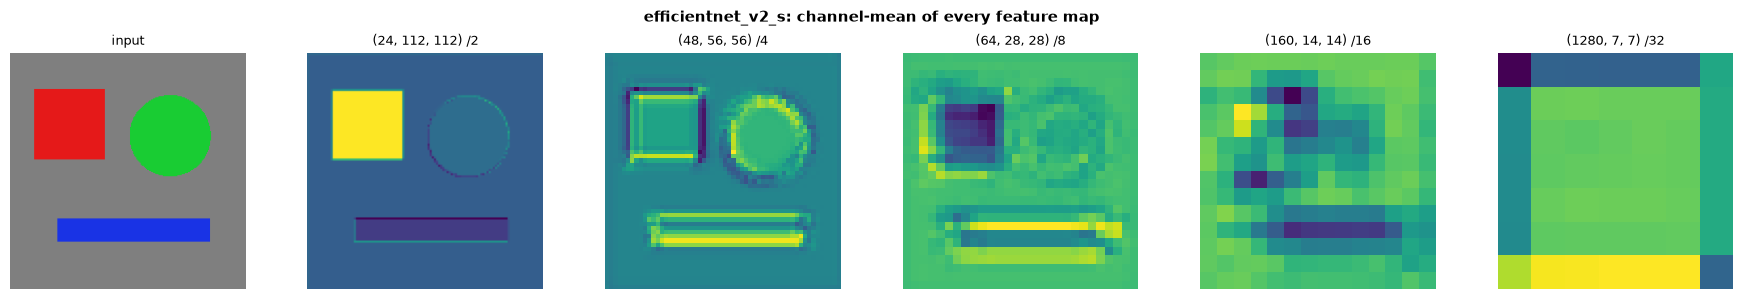

In [24]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [25]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [26]:
import sys

import torch

x = torch.randn(1, 3, 224, 224)

for name in ['efficientnet_v2_s', 'efficientnet_v2_m', 'efficientnet_v2_l']:
    bb = build_vision_backbone(name, img_size=224)
    bb.eval()
    with torch.no_grad():
        out = bb(x)
    print(f'{name:22s}  embed={out.pooled_output.shape[-1]}')
    print(f'  feature_maps: {[tuple(f.shape) for f in out.feature_maps]}')
    print(f'  params: {bb.num_parameters():,}')
    print()

efficientnet_v2_s       embed=1280
  feature_maps: [(1, 24, 112, 112), (1, 48, 56, 56), (1, 64, 28, 28), (1, 160, 14, 14), (1, 1280, 7, 7)]
  params: 38,155,656



efficientnet_v2_m       embed=1280
  feature_maps: [(1, 24, 112, 112), (1, 48, 56, 56), (1, 80, 28, 28), (1, 176, 14, 14), (1, 1280, 7, 7)]
  params: 101,387,912



efficientnet_v2_l       embed=1280
  feature_maps: [(1, 32, 112, 112), (1, 64, 56, 56), (1, 96, 28, 28), (1, 224, 14, 14), (1, 1280, 7, 7)]
  params: 226,284,304



## References

1. **[Primary]** Tan, M., & Le, Q. V. (2021). **EfficientNetV2: Smaller Models and Faster Training**. *ICML 2021*. https://arxiv.org/abs/2104.00298

2. Tan, M., & Le, Q. V. (2019). **EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks**. *ICML 2019*. https://arxiv.org/abs/1905.11946 — The V1 that V2 builds on.

3. Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). **MobileNetV2: Inverted Residuals and Linear Bottlenecks**. *CVPR 2018*. — The MBConv block used in EfficientNet.

4. Hu, J., Shen, L., & Sun, G. (2018). **Squeeze-and-Excitation Networks**. *CVPR 2018*. — The SE block used in EfficientNet for channel attention.

5. Huang, G., Sun, Y., Liu, Z., Sedra, D., & Weinberger, K. (2016). **Deep Networks with Stochastic Depth**. *ECCV 2016*. — Stochastic depth (DropPath) regularisation.